# 01 · Exploratory analysis and KPI validation

**Business questions**
1. How fast is the marketplace growing, and where does the revenue come from?
2. How good is the delivery experience, and how much does it affect customer satisfaction?
3. Do customers come back?

This notebook works on the star schema produced by `src/build_star_schema.py`, so every number here
should match the Power BI report. The **KPI validation table** below is the reference used to check the DAX measures.

Analysis window: purchases from **2017-01-01 to 2018-08-31** (20 complete months). All money values are in Brazilian reais (R$).

In [1]:
import sys
from pathlib import Path

import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import chart_style as cs

cs.apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

P = ROOT / "data" / "processed"
items = pd.read_csv(P / "FactOrderItems.csv", parse_dates=["OrderDate"])
orders = pd.read_csv(P / "FactOrders.csv", parse_dates=["OrderDate", "DeliveredDate", "EstimatedDate"])
customers = pd.read_csv(P / "DimCustomer.csv")
products = pd.read_csv(P / "DimProduct.csv")
sellers = pd.read_csv(P / "DimSeller.csv")
{name: len(df) for name, df in [("FactOrderItems", items), ("FactOrders", orders), ("DimCustomer", customers), ("DimProduct", products), ("DimSeller", sellers)]}

{'FactOrderItems': 111752,
 'FactOrders': 99092,
 'DimCustomer': 95774,
 'DimProduct': 32951,
 'DimSeller': 3095}

## Data quality issues found in the raw data (and how the ETL handles them)

| Issue | Impact if ignored | Fix in `build_star_schema.py` |
|---|---|---|
| `customer_id` is generated **per order**; the real person is `customer_unique_id` | Every customer looks like a one-time buyer, repeat rate = 0% | DimCustomer is keyed on `customer_unique_id` |
| 547 orders have more than one review | Review KPIs double-count those orders | Keep the most recent review per order |
| 2016 and Sep–Oct 2018 have very few orders | Misleading growth rates and trends | Analysis window Jan 2017 – Aug 2018 |
| 610 products have no category; 2 categories have no English translation | Blank or Portuguese labels in visuals | Mapped to "Unknown" and manual translations |
| Canceled / unavailable orders still appear in the orders table | Revenue overstated | Kept in FactOrders (for cancellation rate) but excluded from FactOrderItems (revenue) |
| Estimated delivery is a date, delivery is a timestamp | Orders delivered *on* the estimated day counted as late (8.1% vs 6.8%) | Lateness compared at date level |
| Geolocation table has many points per zip code, some outside Brazil | Wrong distances | Median point per zip prefix, points outside Brazil's bounding box dropped |
| Seller city is free text ("sao paulo - sp", "maua/sao paulo", even an e-mail address) and has accents | Same city appears under many spellings | Text before any separator kept, accents stripped, junk values set to "Unknown" |
| Order and customer IDs are 32-character hashes | Large, slow Power BI model | Integer surrogate keys |

## KPI validation table

These are the values the Power BI measures should return. "2017 YTD" and "2018 YTD" both cover **January–August**
so the year-over-year comparison is like-for-like (the data stops at the end of August 2018).

In [2]:
def kpis(start: str, end: str) -> dict:
    """Compute every headline KPI for purchases between start and end (inclusive)."""
    it = items[items["OrderDate"].between(start, end)]
    od = orders[orders["OrderDate"].between(start, end)]
    revenue, freight = it["Price"].sum(), it["Freight"].sum()
    n_orders = it["OrderKey"].nunique()
    orders_per_customer = it.groupby("CustomerKey")["OrderKey"].nunique()
    seller_rev = it.groupby("SellerKey")["Price"].sum().sort_values(ascending=False)
    top_n = int(np.ceil(len(seller_rev) * 0.10))
    delivered = od[od["IsDelivered"] == 1]
    return {
        "Revenue (R$)": revenue,
        "Freight Revenue (R$)": freight,
        "GMV (R$)": revenue + freight,
        "Orders": n_orders,
        "Items Sold": len(it),
        "Avg Order Value (R$)": revenue / n_orders,
        "Items per Order": len(it) / n_orders,
        "Freight % of Revenue": freight / revenue,
        "Active Customers": it["CustomerKey"].nunique(),
        "Active Sellers": it["SellerKey"].nunique(),
        "Repeat Customer Rate": (orders_per_customer > 1).mean(),
        "Cancellation Rate": od["IsCanceled"].mean(),
        "Delivered Orders": len(delivered),
        "Late Delivery Rate": delivered["IsLate"].mean(),
        "On-Time Delivery Rate": 1 - delivered["IsLate"].mean(),
        "Avg Delivery Days": delivered["DeliveryDays"].mean(),
        "Avg Review Score": od["ReviewScore"].mean(),
        "Bad Review Rate (1-2 stars)": od["IsBadReview"].mean(),
        "Top 10% Sellers Revenue Share": seller_rev.head(top_n).sum() / revenue,
    }

validation = pd.DataFrame(
    {
        "All data (Jan 2017 - Aug 2018)": kpis("2017-01-01", "2018-08-31"),
        "2017 YTD (Jan-Aug)": kpis("2017-01-01", "2017-08-31"),
        "2018 YTD (Jan-Aug)": kpis("2018-01-01", "2018-08-31"),
    }
)
validation["YoY change"] = validation["2018 YTD (Jan-Aug)"] / validation["2017 YTD (Jan-Aug)"] - 1
validation.to_csv(ROOT / "docs" / "kpi_expected_values.csv")
validation

,All data (Jan 2017 - Aug 2018),2017 YTD (Jan-Aug),2018 YTD (Jan-Aug),YoY change
Revenue (R$),"13,449,529.680","3,080,850.810","7,341,037.410",1.383
Freight Revenue (R$),"2,238,866.960","494,223.990","1,254,633.860",1.539
GMV (R$),"15,688,396.640","3,575,074.800","8,595,671.270",1.404
Orders,"97,905.000","22,562.000","53,530.000",1.373
Items Sold,"111,752.000","25,576.000","61,135.000",1.390
Avg Order Value (R$),137.373,136.550,137.139,0.004
Items per Order,1.141,1.134,1.142,0.007
Freight % of Revenue,0.166,0.160,0.171,0.065
Active Customers,"94,703.000","21,936.000","52,336.000",1.386
Active Sellers,"3,029.000","1,212.000","2,354.000",0.942


## 1 · Growth: revenue more than doubled year over year

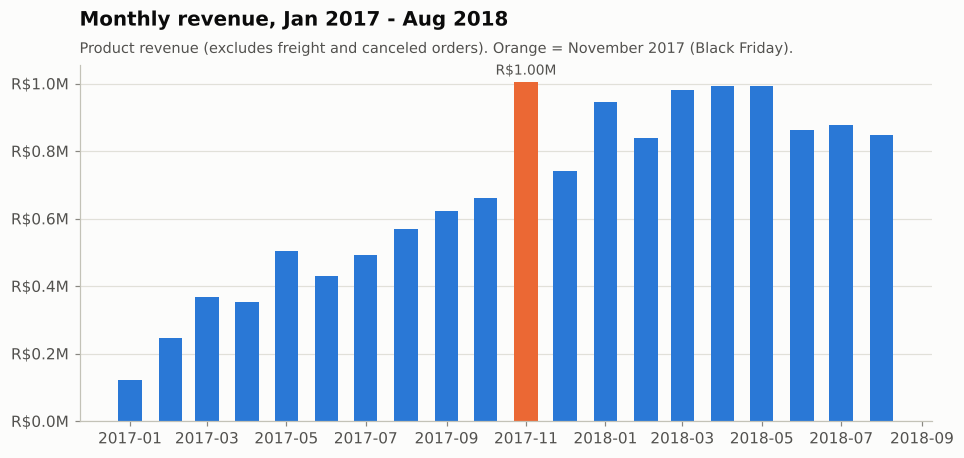

In [3]:
monthly = items.groupby(items["OrderDate"].dt.to_period("M")).agg(Revenue=("Price", "sum"), Orders=("OrderKey", "nunique"))
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4.2))
bar_colors = [cs.ORANGE if d == pd.Timestamp("2017-11-01") else cs.BLUE for d in monthly.index]
ax.bar(monthly.index, monthly["Revenue"], width=18, color=bar_colors)
ax.yaxis.set_major_formatter(cs.brl_millions())
ax.grid(axis="x", visible=False)
ax.set_title("Monthly revenue, Jan 2017 - Aug 2018")
cs.subtitle(ax, "Product revenue (excludes freight and canceled orders). Orange = November 2017 (Black Friday).")
nov = monthly.loc["2017-11-01", "Revenue"]
ax.annotate(f"R${nov / 1e6:.2f}M", (pd.Timestamp("2017-11-01"), nov), textcoords="offset points", xytext=(0, 5),
            ha="center", color=cs.INK_SECONDARY, fontsize=9)
cs.save(fig, "01_monthly_revenue.png")
plt.show()

In [4]:
daily = items.groupby("OrderDate")["OrderKey"].nunique()
print(f"Busiest day: {daily.idxmax():%A %d %b %Y} with {daily.max():,} orders "
      f"({daily.max() / daily['2017-11'].median():.1f}x the November median day)")
print(f"Revenue YoY (Jan-Aug): {validation.loc['Revenue (R$)', 'YoY change']:+.1%}  |  "
      f"Orders YoY: {validation.loc['Orders', 'YoY change']:+.1%}  |  "
      f"AOV YoY: {validation.loc['Avg Order Value (R$)', 'YoY change']:+.1%}")

Busiest day: Friday 24 Nov 2017 with 1,166 orders (6.3x the November median day)
Revenue YoY (Jan-Aug): +138.3%  |  Orders YoY: +137.3%  |  AOV YoY: +0.4%


Growth is driven by **volume, not basket size**: orders grew about as fast as revenue while average order value stayed flat.

## 2 · Where the revenue comes from

74 categories; top 10 = 62.4% of revenue


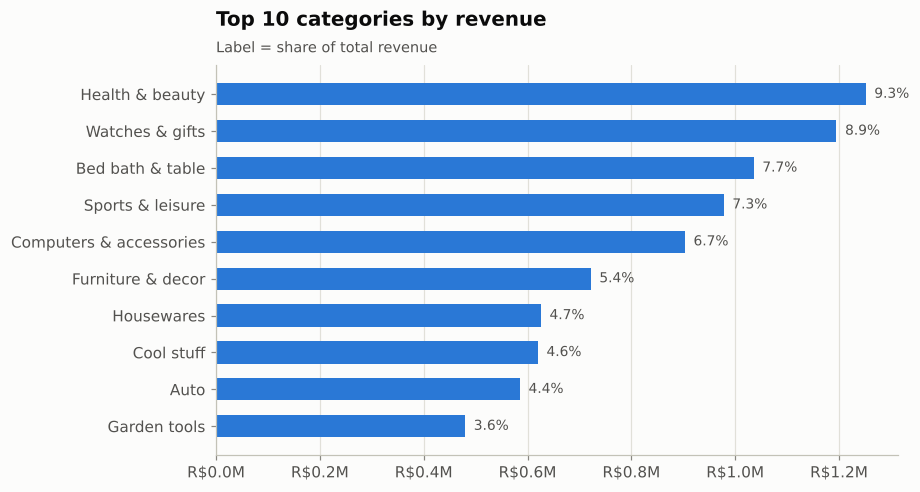

In [5]:
cat_rev = (
    items.merge(products[["ProductKey", "Category"]], on="ProductKey")
    .groupby("Category")["Price"].sum().sort_values(ascending=False)
)
top10 = cat_rev.head(10)
print(f"{cat_rev.size} categories; top 10 = {top10.sum() / cat_rev.sum():.1%} of revenue")

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top10.index[::-1], top10.values[::-1], height=0.6, color=cs.BLUE)
ax.xaxis.set_major_formatter(cs.brl_millions())
ax.grid(axis="y", visible=False)
for y, v in enumerate(top10.values[::-1]):
    ax.text(v, y, f"  {v / cat_rev.sum():.1%}", va="center", color=cs.INK_SECONDARY, fontsize=9)
ax.set_title("Top 10 categories by revenue")
cs.subtitle(ax, "Label = share of total revenue")
cs.save(fig, "02_top_categories.png")
plt.show()

In [6]:
seller_rev = items.groupby("SellerKey")["Price"].sum().sort_values(ascending=False)
cum_share = seller_rev.cumsum() / seller_rev.sum()
for pct_sellers in (0.01, 0.10, 0.20):
    n = int(np.ceil(len(seller_rev) * pct_sellers))
    print(f"Top {pct_sellers:.0%} of sellers ({n:,}) generate {cum_share.iloc[n - 1]:.1%} of revenue")

Top 1% of sellers (31) generate 26.2% of revenue
Top 10% of sellers (303) generate 67.4% of revenue
Top 20% of sellers (606) generate 82.5% of revenue


## 3 · Delivery experience drives satisfaction

The single strongest pattern in the data: **once an order is late, the review score collapses.**

In [7]:
delivered = orders[orders["IsDelivered"] == 1]
by_bucket = (
    delivered.groupby(["DelayBucketSort", "DelayBucket"])
    .agg(Orders=("OrderKey", "size"), AvgReview=("ReviewScore", "mean"), BadReviewRate=("IsBadReview", "mean"))
    .reset_index(level=0, drop=True)
)
by_bucket

,Orders,AvgReview,BadReviewRate
DelayBucket,,,
15+ days early,34693,4.325,0.090
8-14 days early,36353,4.311,0.089
1-7 days early,17335,4.201,0.102
On the estimated day,1291,4.034,0.124
1-3 days late,1869,3.291,0.321
4-7 days late,1802,2.103,0.677
8+ days late,2860,1.697,0.793


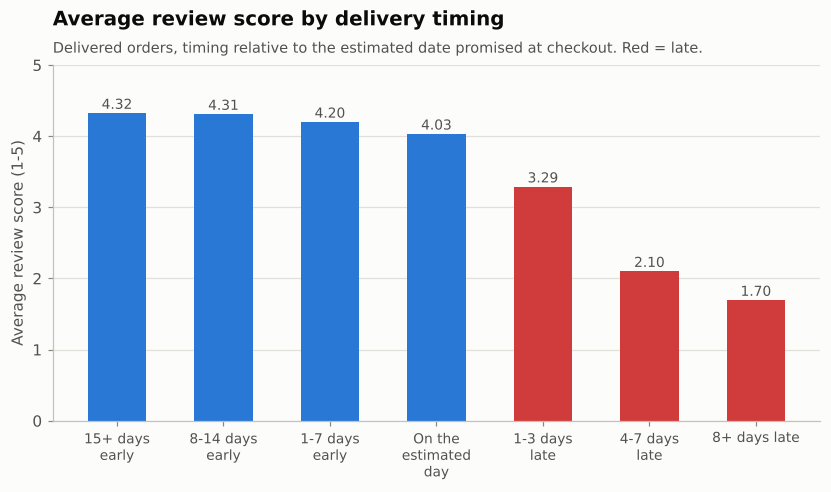

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [cs.CRITICAL if "late" in b else cs.BLUE for b in by_bucket.index]
labels = [textwrap.fill(b, 12) for b in by_bucket.index]
ax.bar(labels, by_bucket["AvgReview"], width=0.55, color=colors)
for x, v in enumerate(by_bucket["AvgReview"]):
    ax.text(x, v + 0.06, f"{v:.2f}", ha="center", color=cs.INK_SECONDARY, fontsize=9)
ax.set_ylim(0, 5)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", labelsize=9)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("Average review score by delivery timing")
cs.subtitle(ax, "Delivered orders, timing relative to the estimated date promised at checkout. Red = late.")
cs.save(fig, "03_review_by_delivery_timing.png")
plt.show()

### Is the difference statistically significant?
Review scores are ordinal, so a Mann-Whitney U test is used rather than a t-test.
For the bad-review rate (a proportion) a chi-square test and a 95% confidence interval for the difference are reported.

In [9]:
rated = delivered.dropna(subset=["ReviewScore"])
late, on_time = rated[rated["IsLate"] == 1], rated[rated["IsLate"] == 0]
u_stat, u_p = stats.mannwhitneyu(late["ReviewScore"], on_time["ReviewScore"], alternative="less")
table = pd.crosstab(rated["IsLate"], rated["IsBadReview"])
chi2, chi_p, _, _ = stats.chi2_contingency(table)
p1, p0 = late["IsBadReview"].mean(), on_time["IsBadReview"].mean()
se = np.sqrt(p1 * (1 - p1) / len(late) + p0 * (1 - p0) / len(on_time))
fmt_p = lambda v: "p < 0.001" if v < 0.001 else f"p = {v:.3f}"
print(f"Avg review: late {late['ReviewScore'].mean():.2f} vs on time {on_time['ReviewScore'].mean():.2f}  (Mann-Whitney U, {fmt_p(u_p)})")
print(f"Bad review rate: late {p1:.1%} vs on time {p0:.1%}  ->  difference {p1 - p0:.1%} "
      f"(95% CI {p1 - p0 - 1.96 * se:.1%} to {p1 - p0 + 1.96 * se:.1%}, chi-square {fmt_p(chi_p)})")
print(f"A late order is {p1 / p0:.1f}x as likely to receive a 1-2 star review.")

Avg review: late 2.27 vs on time 4.29  (Mann-Whitney U, p < 0.001)
Bad review rate: late 62.4% vs on time 9.2%  ->  difference 53.2% (95% CI 52.0% to 54.4%, chi-square p < 0.001)
A late order is 6.7x as likely to receive a 1-2 star review.


*Caveat for interviews:* this is an observational association. Late orders may differ in other ways
(region, product size), so this ratio is not a pure causal effect. The pattern holds within every region (table below), which makes a causal story plausible.

In [10]:
rated_reg = rated.merge(customers[["CustomerKey", "Region"]], on="CustomerKey")
rated_reg.pivot_table(index="Region", columns="IsLate", values="IsBadReview", aggfunc="mean").rename(
    columns={0: "Bad review rate - on time", 1: "Bad review rate - late"}
).style.format("{:.1%}")

IsLate,Bad review rate - on time,Bad review rate - late
Region,,
Central-West,9.6%,64.1%
North,10.6%,66.2%
Northeast,9.9%,64.9%
South,8.8%,59.7%
Southeast,9.2%,62.0%


## 4 · Where and when deliveries are late

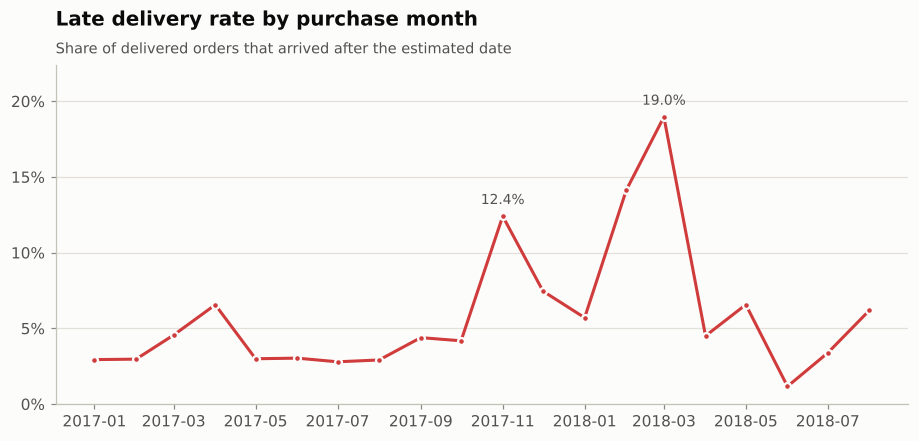

In [11]:
monthly_late = delivered.groupby(delivered["OrderDate"].dt.to_period("M"))["IsLate"].mean()
monthly_late.index = monthly_late.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly_late.index, monthly_late.values, color=cs.CRITICAL, marker="o", markersize=4.5,
        markeredgecolor=cs.SURFACE, markeredgewidth=1.5)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(cs.pct())
ax.set_ylim(0, monthly_late.max() * 1.18)
ax.grid(axis="x", visible=False)
for d in ["2017-11-01", "2018-03-01"]:
    d = pd.Timestamp(d)
    ax.annotate(f"{monthly_late[d]:.1%}", (d, monthly_late[d]), textcoords="offset points", xytext=(0, 8),
                ha="center", color=cs.INK_SECONDARY, fontsize=9)
ax.set_title("Late delivery rate by purchase month")
cs.subtitle(ax, "Share of delivered orders that arrived after the estimated date")
cs.save(fig, "04_late_rate_by_month.png")
plt.show()

Lateness is **not stable over time**: it spikes after the Black Friday peak (Nov 2017) and again in Feb–Mar 2018.
Comparing like-for-like periods, the late rate roughly **doubled from 3.5% (Jan–Aug 2017) to 7.7% (Jan–Aug 2018)** while order volume grew 137%:
logistics capacity did not keep up with growth.

This also matters for the prediction model: the late rate in the test months is different from the training months (data drift).

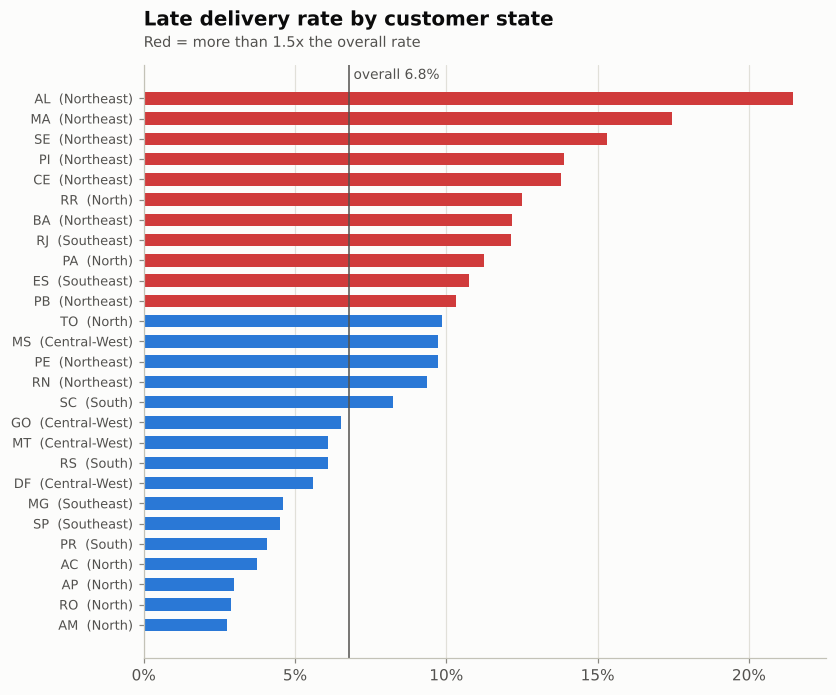

In [12]:
state_late = (
    delivered.merge(customers[["CustomerKey", "State", "Region"]], on="CustomerKey")
    .groupby(["State", "Region"]).agg(Orders=("OrderKey", "size"), LateRate=("IsLate", "mean"), AvgDays=("DeliveryDays", "mean"))
    .reset_index().sort_values("LateRate")
)
overall = delivered["IsLate"].mean()

fig, ax = plt.subplots(figsize=(8, 7))
colors = [cs.CRITICAL if r > overall * 1.5 else cs.BLUE for r in state_late["LateRate"]]
ax.barh(state_late["State"] + "  (" + state_late["Region"] + ")", state_late["LateRate"], height=0.62, color=colors)
ax.axvline(overall, color=cs.INK_SECONDARY, linewidth=1)
ax.text(overall, len(state_late) - 0.2, f" overall {overall:.1%}", color=cs.INK_SECONDARY, fontsize=9, va="bottom")
ax.xaxis.set_major_formatter(cs.pct())
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
ax.set_title("Late delivery rate by customer state")
cs.subtitle(ax, "Red = more than 1.5x the overall rate")
cs.save(fig, "05_late_rate_by_state.png")
plt.show()

In [13]:
dist = delivered.dropna(subset=["DistanceKm"]).copy()
dist["DistanceBand"] = pd.cut(dist["DistanceKm"], [0, 100, 300, 600, 1000, 2000, 5000],
                              labels=["<100 km", "100-300", "300-600", "600-1,000", "1,000-2,000", "2,000+"], include_lowest=True)
dist.groupby("DistanceBand", observed=True).agg(
    Orders=("OrderKey", "size"), AvgDeliveryDays=("DeliveryDays", "mean"),
    AvgPromisedDays=("PromisedDays", "mean"), LateRate=("IsLate", "mean")
)

,Orders,AvgDeliveryDays,AvgPromisedDays,LateRate
DistanceBand,,,,
<100 km,17758,6.484,15.838,0.045
100-300,13275,9.979,21.334,0.052
300-600,31427,12.594,24.861,0.068
"600-1,000",17921,14.674,27.399,0.071
"1,000-2,000",9739,17.921,30.682,0.095
"2,000+",5604,21.131,33.679,0.120


Lateness is concentrated in the **Northeast** (AL, MA, SE, PI, CE) and in **Rio de Janeiro**, a large market where 12% of orders arrive late.
Most of the North has low late rates, but few orders.

Olist's delivery estimate already pads long routes (promised days rise with distance), yet the late rate still climbs with distance.
Distance and the customer's state are therefore useful **features for predicting late orders** (notebook 02).

## 5 · Retention: almost every customer buys once

In [14]:
it = items[items["OrderDate"].between("2017-01-01", "2018-08-31")]
orders_per_customer = it.groupby("CustomerKey")["OrderKey"].nunique()
print(f"Customers: {orders_per_customer.size:,}")
print(f"Bought more than once: {(orders_per_customer > 1).sum():,} ({(orders_per_customer > 1).mean():.1%})")
repeat_orders = orders[(orders["IsCanceled"] == 0)]["IsRepeatOrder"].mean()
print(f"Share of orders placed by returning customers: {repeat_orders:.1%}")

Customers: 94,703
Bought more than once: 2,874 (3.0%)
Share of orders placed by returning customers: 3.3%


In [15]:
first = orders[orders["CustomerOrderNumber"] == 1][["CustomerKey", "IsLate", "ReviewScore"]]
came_back = orders[orders["CustomerOrderNumber"] == 2]["CustomerKey"]
first["Returned"] = first["CustomerKey"].isin(came_back)
first.dropna(subset=["ReviewScore"]).groupby("ReviewScore")["Returned"].agg(["mean", "size"]).rename(
    columns={"mean": "Return rate", "size": "Customers"}
).style.format({"Return rate": "{:.2%}", "Customers": "{:,}"})

,Return rate,Customers
ReviewScore,,
1.000000,2.93%,"10,105"
2.000000,2.75%,"2,949"
3.000000,3.02%,"7,772"
4.000000,2.77%,"18,415"
5.000000,3.15%,"54,768"


Surprisingly, the return rate is about 3% **whatever score the first order received** (and whether or not it was late).
In this data, a bad experience shows up in reviews, not in measurably lower repeat buying. One plausible explanation: Olist sells
through large marketplaces, so customers rarely know they are buying from the same store again. Reviews still matter because they
feed the store's rating on those marketplaces.

Being honest about a hypothesis that the data did **not** support is a good interview talking point.

## Summary of findings

1. **Strong growth**: Jan–Aug 2018 revenue was 2.4x Jan–Aug 2017 (+138%), driven by order volume; average order value was flat.
2. **Delivery did not scale with growth**: the late rate doubled from 3.5% to 7.7% over the same period.
3. **Late delivery is the biggest satisfaction risk**: a late order is about 6.7x as likely to get a 1–2 star review (62% vs 9%; statistically significant, and the same pattern appears in every region). Orders 8+ days late average 1.7 stars.
4. **Lateness is concentrated** in the Northeast and Rio de Janeiro and on long-distance routes, and spiked after Black Friday and in Feb–Mar 2018.
5. **Almost every customer buys once** (3% repeat rate), and the first-order experience does not change that.
6. **Revenue is concentrated**: the top 10% of sellers generate about two thirds of revenue.

**Recommendation:** predict late-risk orders at checkout (notebook 02) so operations can intervene before the customer is disappointed, and track late rate and review score as primary KPIs in the Power BI report.